<a href="https://colab.research.google.com/github/emmafaiv/Projet_MP/blob/main/World_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [178]:
import numpy as np
import matplotlib.pyplot as plt

t = (0, 100) # Temps de simulation en années

def blocphysique(pop_0, births_0, deaths_0, capital_indus_0, invest_indus_0, output_indus_0, input_indus_nrr_0, indus_input_intensity_0, fcaor_0, land_agri_tot_0, agri_input_0, agri_pollution_0, invest_agri_0, pollution_0, capital_services_0, output_services_0, invest_services_0, education_0, investment_education_0, nrr_0):
    n = t[1] + 1
    temps = np.arange(n)

    # Initialisation des tableaux
    pop, births, deaths, birth_rate, death_rate, tau_education_birth_control = [np.zeros(n) for _ in range(6)]
    investment_tot, invest_indus, invest_agri, invest_services, investment_education = [np.zeros(n) for _ in range(5)]
    capital_indus, labor_indus, input_indus_nrr, indus_input_efficiency, factor_indus, output_indus, output_conso, output_agri, fcaor, non_fcaor = [np.zeros(n) for _ in range(10)]
    land_agri_tot, agri_input, agri_pollution, agri_productivity, food_production = [np.zeros(n) for _ in range(5)]
    pollution = np.zeros(n)
    capital_services, labor_services, output_services, education, health = [np.zeros(n) for _ in range(5)]
    nrr = np.zeros(n)

    # Conditions initiales
    pop[0], births[0], deaths[0] = pop_0, births_0, deaths_0
    capital_indus[0], invest_indus[0], output_indus[0], input_indus_nrr[0], indus_input_intensity[0], fcaor[0] = capital_indus_0, invest_indus_0, output_indus_0, input_indus_nrr_0, indus_input_intensity_0, fcaor_0
    non_fcaor[0] = capital_indus[0] - fcaor[0]
    land_agri_tot[0], agri_input[0], agri_pollution[0], invest_agri_0 = land_agri_tot_0, agri_input_0, agri_pollution_0, invest_agri_0
    pollution[0] = pollution_0
    capital_services[0], output_services[0], invest_services[0], education[0], investment_education[0] = capital_services_0, output_services_0, invest_services_0, education_0, investment_education_0
    nrr[0] = nrr_0

    # Définition des paramètres
    tau_fertility = 0.017 #Taux de natalité : 17 enfants pour 1000 habitants
    coef_education = 0.001 #Taux de natalité : pas de données robustes pour l'instant, on prend quelque chose de bas
    tau_life_expectancy = 0.02 #80 ans en moyenne
    tau_pollution_mortality = 0.0001 #100 morts pour 100 000 habitants
    tau_death_health = 0.004 #Diminution de la mortalité grâce aux services de santé
    tau_services_health = 0.5 #Part du capital de services dédié à la santé
    tau_services_education = 0.5 #Part du capital de services dédié à l'éducation
    fraction_indus_conso = 0.25 #part de la production industrielle dédiée à la conso
    fraction_indus_agri = 0.05 #part de la production industrielle dédiée à l'agri
    invest_rate_indus = 0.5 #Part de l'investissement dirigé vers l'industrie
    invest_rate_agri = 0.15 #Part de l'investissement dirigé vers l'agriculture --> expansion agricole
    invest_rate_services = 0.25
    tau_technical_progress = 0.01 #1% d'efficacité gagné quotidiennement
    cost_land_conversion = 6
    alpha_indus = 0.3
    alpha_services = 0.3
    labor_fraction_indus = 0.3 #fraction de la population travaillant dans l'industrie
    # labor_fraction_services = 0.5 ne pas
    depreciation = 0.04
    agri_input_toxicity = 0.03
    agri_input_effectiveness = 0.01
    tau_land_per_capita = 0.0001
    pollution_decay = 0.05 #Durée de vie de 20 ans pour la pollution
    indus_toxicity_intensity = 0.005
    tau_effect_pollution_agri = 0.05

    # Boucle temporelle
    for i in range(t[0], t[1]):
        # Bloc population
        pop[i+1] = pop[i] + births[i] - deaths[i]
        tau_education_birth_control[i+1] = coef_education * education[i] / pop[i]
        birth_rate[i+1] = tau_fertility - tau_education_birth_control[i+1]
        births[i+1] = pop[i+1] * birth_rate[i+1]

        death_rate[i+1] = tau_life_expectancy + tau_pollution_mortality * pollution[i] - tau_death_health * health[i] / pop[i+1]
        deaths[i+1] = pop[i+1] * death_rate[i+1]

        # Bloc capital industriel
        capital_indus[i+1] = (capital_indus[i]) * (1 - depreciation) + invest_indus[i]
        fcaor[i+1] = capital_indus[i+1]*input_indus_nrr[i+1]*(1-(nrr_0-nrr[i+1])/nrr_0) #fraction du capital alloué à l'obtention de ressources --> rétroaction négative (LtG, c'est une interpolation)
        non_fcaor[i+1] = capital_indus[i+1] - fcaor[i+1]

        labor_indus[i+1] = pop[i+1] * labor_fraction_indus #Emplois dans l'industrie

        output_indus[i+1] = factor_indus[i+1] * (non_fcaor[i+1]**alpha_indus) * (labor_indus[i+1]**(1-alpha_indus)) #Production industrielle/an
        output_conso[i+1] = output_indus[i+1] * fraction_indus_conso #Fraction de la production industrielle dédiée à la conso/industrie --> à rendre dynamique?
        output_agri[i+1] = output_indus[i+1] * fraction_indus_agri #Fraction de la production industrielle dédiée à l'agriculture --> à rendre dynamique?

        investment_tot[i+1] = output_indus[i+1] * (1 - fraction_indus_conso - fraction_indus_agri)
        invest_indus[i+1] = investment_tot[i+1] * invest_rate_indus
        invest_agri[i+1] = investment_tot[i+1] * invest_rate_agri
        invest_services[i+1] = investment_tot[i+1] * (1 - invest_rate_indus - invest_rate_agri) #seuls l'investissement fait croitre les services

        indus_input_efficiency[i+1] = indus_input_efficiency[i] * (1 + tau_technical_progress)
        input_indus_nrr[i+1] = output_indus[i+1] * indus_input_efficiency[i+1]


        # Bloc agriculture
        land_agri_tot[i+1] = land_agri_tot[i] * (1 + invest_rate_agri * invest_agri[i] / cost_land_conversion + tau_land_per_capita*pop[i])
        agri_input[i+1] = output_agri[i+1] #La production destinée à l'agriculture représente uniquement des intrants
        agri_pollution[i+1] = agri_pollution[i] * (1 - pollution_decay) + pollution[i]/ land_agri_tot[i]
        agri_productivity[i+1] = agri_input[i+1] * agri_input_effectiveness - agri_pollution[i+1] * land_agri_tot[i+1]*tau_effect_pollution_agri
        food_production[i+1] = land_agri_tot[i+1] * agri_productivity[i+1]

        # Bloc pollution
        pollution[i+1] = pollution[i] * (1 - pollution_decay) + agri_input[i] * agri_input_toxicity + output_indus[i] * indus_toxicity_intensity

        # Bloc capital de services
        capital_services[i+1] = capital_services[i] + invest_services[i]
        health[i+1]=capital_services[i+1]*tau_services_health
        education[i+1]=capital_services[i+1]*tau_services_education

        # Bloc NRR
        nrr[i+1] = max(nrr[i] - input_indus_nrr[i], 0)

    return temps, pop, nrr, capital_indus, pollution, food_production

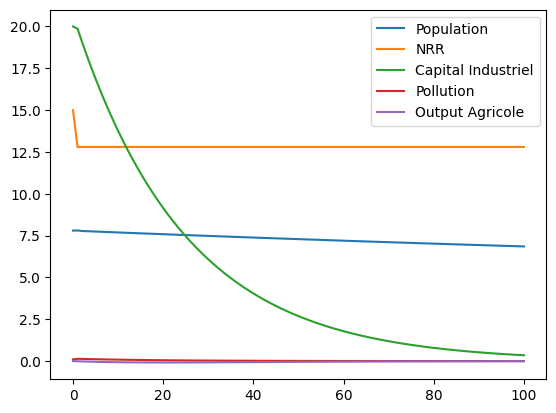

In [176]:
# Définiton des CI - test 1
pop_0,births_0,deaths_0=7.8,0.017,0.01
capital_indus_0,invest_indus_0,output_indus_0,input_indus_nrr_0,indus_input_intensity_0,fcaor_0=20,0.67,4.45,2.2,0.5,0.1
land_agri_tot_0,agri_input_0,agri_pollution_0,invest_agri_0=1.5,0.67,0.01,0.2
pollution_0=0.1
capital_services_0,output_services_0,invest_services_0,education_0,investment_education_0=8,4.4,0.33,8,0.13
nrr_0=15

# Appel de la fonction avec les conditions initiales
temps, pop, nrr, capital_indus, pollution, output_agri = blocphysique(
pop_0,births_0,deaths_0,capital_indus_0,invest_indus_0,output_indus_0,input_indus_nrr_0,indus_input_intensity_0,fcaor_0,
land_agri_tot_0,agri_input_0,agri_pollution_0,invest_agri_0,pollution_0,capital_services_0,output_services_0,invest_services_0,education_0,investment_education_0,
nrr_0
)

plt.plot(temps,pop,label='Population')
plt.plot(temps,nrr,label='NRR')
plt.plot(temps,capital_indus,label='Capital Industriel')
plt.plot(temps,pollution,label='Pollution')
plt.plot(temps,output_agri,label='Output Agricole')
plt.legend()
plt.show()

In [174]:
# Appel de la fonction avec les conditions initiales
temps, pop, nrr, capital_indus, pollution, output_agri = blocphysique(
    7.8, 0.017, 0.01, 20, 0.67, 4.45, 2.2, 0.5, 0.2, 1.5, 0.67, 0.01, 0.2, 0.1, 8, 4.4, 0.33, 8, 0.13, 1
)

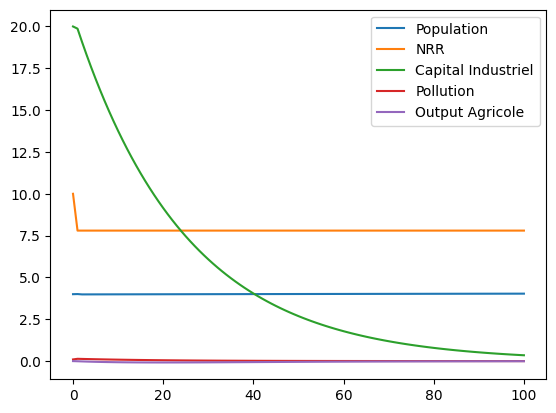

In [171]:
# Définiton des CI - test 2
pop_0,births_0,deaths_0=4,0.017,0.01
capital_indus_0,invest_indus_0,output_indus_0,input_indus_nrr_0,indus_input_intensity_0,fcaor_0=20,0.67,4.45,2.2,0.5,0.1
land_agri_tot_0,agri_input_0,agri_pollution_0,invest_agri_0=1.5,0.67,0.01,0.2
pollution_0=0.1
capital_services_0,output_services_0,invest_services_0,education_0,investment_education_0=8,4.4,0.33,8,0.13
nrr_0=10

# Appel de la fonction avec les conditions initiales
temps, pop, nrr, capital_indus, pollution, output_agri = blocphysique(
pop_0,births_0,deaths_0,capital_indus_0,invest_indus_0,output_indus_0,input_indus_nrr_0,indus_input_intensity_0,fcaor_0,
land_agri_tot_0,agri_input_0,agri_pollution_0,invest_agri_0,pollution_0,capital_services_0,output_services_0,invest_services_0,education_0,investment_education_0,
nrr_0
)

plt.plot(temps,pop,label='Population')
plt.plot(temps,nrr,label='NRR')
plt.plot(temps,capital_indus,label='Capital Industriel')
plt.plot(temps,pollution,label='Pollution')
plt.plot(temps,output_agri,label='Output Agricole')
plt.legend()
plt.show()

In [144]:

# Définiton des CI - test 1
pop_0,births_0,deaths_0=7.8,0.017,0.01
capital_indus_0,invest_indus_0,output_indus_0,input_indus_nrr_0,indus_input_intensity_0=20,0.67,4.45,2.2,0.5
land_agri_tot_0,agri_input_0,agri_pollution_0,invest_agri_0=1.5,0.67,0.01,0.2
pollution_0=0
capital_services_0,output_services_0,invest_services_0,education_0,investment_education_0=8,4.4,0.33,8,0.13
nrr_0=150 #en

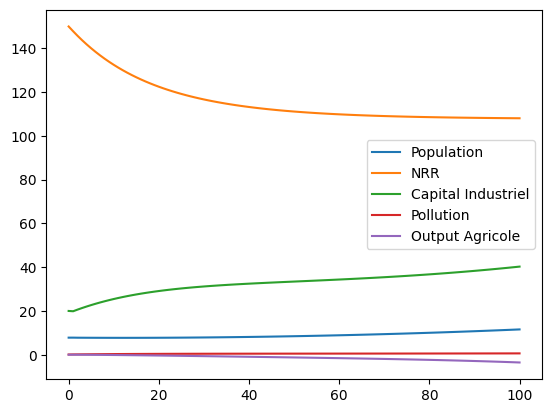

In [145]:

plt.plot(temps,pop,label='Population')
plt.plot(temps,nrr,label='NRR')
plt.plot(temps,capital_indus,label='Capital Industriel')
plt.plot(temps,pollution,label='Pollution')
plt.plot(temps,output_agri,label='Output Agricole')
plt.legend()
plt.show()

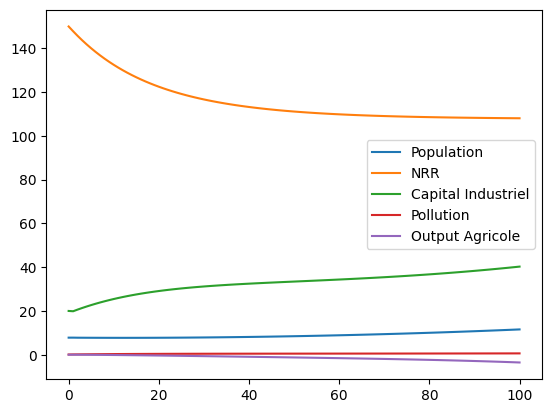

In [143]:
plt.plot(temps,pop,label='Population')
plt.plot(temps,nrr,label='NRR')
plt.plot(temps,capital_indus,label='Capital Industriel')
plt.plot(temps,pollution,label='Pollution')
plt.plot(temps,output_agri,label='Output Agricole')
plt.legend()
plt.show()

In [73]:
# Appel de la fonction avec les conditions initiales
temps, pop, nrr, capital_indus, pollution, output_agri = blocphysique(
    7.8, 0.017, 0.01, 20, 0.67, 4.45, 2.2, 0.5, 1.5, 0.67, 0.01, 0.2, 0.1, 8, 4.4, 0.33, 8, 0.13, 150
)
